# Notebook 01 — Raw Cryo-EM Preprocessing and Frozen Particle-Level Data Split

This notebook prepares the raw cryo-electron microscopy (cryo-EM) particle and noise images and establishes the **fixed particle-level data split** used in later notebooks. It reads the original MRC image stacks and STAR metadata, checks particle identifiers and original stack indices, and previews representative raw images.

It also examines STAR-based particle recentering and applies Gaussian low-pass filtering to a small preview and, optionally, the full dataset of **57,107 particles**. Large arrays can be processed in batches using memory-mapped files so that the full image stack does not have to fit in RAM. Processed images and metadata are saved as reusable checkpoints.

The notebook creates or records a **frozen validation manifest** (`outputs/validation/cv_3fold_with_unknown_test.csv`): **5,711 particles in held-out Fold 0** and **17,132 particles in each of Folds 1–3** for cross-validation. The split is made at the particle level, because micrograph-level identifiers are unavailable. Each fold assignment is stored with its `particle_id` and `stack_index_1based`.

**Critical ordering rule:** STAR rows and original MRC stack positions are not interchangeable. The optional `raw_particles_star_order.npy` file is deliberately arranged in **STAR row order** for raw-image preprocessing. By contrast, Camille's CWF stack used downstream follows **original MRC stack order**. Notebook 02b matches particles using their identifiers and original stack indices; Notebook 09 reuses the frozen split without assuming that STAR and CWF row positions match.

**Downstream role:** Notebook 02b uses the frozen particle mapping and split information, whereas the final CWF-based feature and clustering pipeline (Notebooks 03 and 09) does **not** directly use the STAR-ordered low-pass image array. The underlying raw MRC and STAR input files are external data and are not included in the repository.

**Execution note for this original version:** Some cells use machine-specific paths and may stop if an output file already exists. 

This notebook is extracted from: expeirment.ipynb (original cells 0-10). The original markdown is kept in all sections.


# 1. Load and display raw particles and noise

Use the project `.venv` kernel. Run section 1, then either method section. Only `tam_dimer_tetramer/batch_0_restacked.mrc`, its STAR metadata, and `noise_restacked.mrc` are used. Select `particle_count` particles in STAR order and load all noise images. Preview a small subset; keep original pixels and metadata for both methods.

Long implementation helpers live in [latent_methods.py](latent_methods.py). The notebook contains settings, execution, and comparisons. Filtering below saves a new reusable input checkpoint for section 2.

## 1.1. Load and display raw images


**Saved results and restarting:** Sections 1–3 save their processed image/feature datasets. Section 4 now saves PCA scores, numerical model arrays, IDs, source checkpoint and plots; set `cwf_pca_load_saved=True` in 4.1 to reload. Sections 5/6 save named clustering checkpoints and automatically restore saved PCA if no PCA is in memory. Section 7 saves ICA scores/transforms and clustering; `cwf_ica_load_saved=True` restores ICA for later clustering. Section 8 can start in a fresh kernel: choose `cwf_view_method` and optionally `cwf_view_checkpoint` to restore a saved result, then display/export images and averages.

All runs use separate folders under `outputs/`; new runs preserve old checkpoints. `latest_pca.json`, `latest_ica.json`, and `clustering_index.json` locate the latest saved results. Explicit checkpoint directories select older runs. Numerical checkpoints use NumPy/JSON/CSV rather than pickled Python objects. Already-computed results from before this change must be saved once by rerunning their producing cells.


In [2]:
#check 
from pathlib import Path

# MODIFIED: Locate the project relative to the current Jupyter directory.
# Works when Jupyter starts in ml4ls/ or a subdirectory of it.
working_directory = Path.cwd().resolve()
base = next(
    (p for p in (working_directory, *working_directory.parents)
     if (p / "latent_methods.py").is_file()),
    None,
)
if base is None:
    raise FileNotFoundError(
        "Cannot find the ML4LS project root (latent_methods.py). "
        "Start Jupyter in the cloned repository or a subdirectory."
    )

# ADDED: Shared path variables for subsequent notebook cells.
project_root = base
output_root = project_root / "outputs"

files = {
    "Particle images": base / "batch_0_restacked.mrc",
    "STAR metadata": base / "J599_split_0_exported.star",
    "Noise images": base / "noise_restacked.mrc",
    "Helper module": base / "latent_methods.py",
}

for name, path in files.items():
    print(f"{name}:")
    print(f"  Exists: {path.exists()}")
    print(f"  Path: {path}")

Particle images:
  Exists: True
  Path: /Users/kr/ml4ls/batch_0_restacked.mrc
STAR metadata:
  Exists: True
  Path: /Users/kr/ml4ls/J599_split_0_exported.star
Noise images:
  Exists: True
  Path: /Users/kr/ml4ls/noise_restacked.mrc
Helper module:
  Exists: True
  Path: /Users/kr/ml4ls/latent_methods.py


In [3]:
from pathlib import Path

# MODIFIED: Reuse the detected project directory.
base = project_root

targets = {
    "latent_methods.py",
    "noise_restacked.mrc",
}

for name in targets:
    print(f"\nSearching for {name}...")

    matches = list(base.rglob(name))

    if matches:
        for path in matches:
            print("FOUND:", path)
    else:
        print("NOT FOUND")


Searching for latent_methods.py...
FOUND: /Users/kr/ml4ls/latent_methods.py

Searching for noise_restacked.mrc...
FOUND: /Users/kr/ml4ls/noise_restacked.mrc


In [6]:
%pip install starfile

Note: you may need to restart the kernel to use updated packages.


In [1]:
import starfile

print("starfile installed successfully!")

starfile installed successfully!


In [2]:
import inspect
import sys

# MODIFIED: Use the detected project directory for local imports.
sys.path.insert(0, str(project_root))

from latent_methods import load_raw_dataset

print(inspect.getsource(load_raw_dataset))

def load_raw_dataset(star_path, stack_path, stack_reference, noise_path,
                     particle_count=2000, batch_size=32):
    """Return raw float32 images and matching provenance, without denoising."""
    if particle_count < 2 or batch_size < 1:
        raise ValueError("Need at least two particles and a positive batch size.")
    tables = starfile.read(star_path, always_dict=True)
    particles = tables["particles"]
    refs = particles["rlnImageName"].astype(str).str.split("@", n=1, expand=True)
    if refs.shape[1] != 2 or refs[1].isna().any():
        raise ValueError("Invalid STAR image references; expected index@stack.")
    selected = particles.loc[refs[1] == stack_reference].head(particle_count).copy()
    if len(selected) != particle_count:
        raise ValueError(f"Requested {particle_count} particles; found only {len(selected)}.")
    selected = selected.reset_index(drop=True)
    indices = selected["rlnImageName"].str.split("@", n=1).str[0].astype(np.int64).to_nu

In [3]:
import mrcfile

# MODIFIED: Build the file path from the project root.
noise_path = str(project_root / "noise_restacked.mrc")

with mrcfile.mmap(noise_path, mode="r") as mrc:
    print("Noise shape:", mrc.data.shape)
    print("Noise data type:", mrc.data.dtype)

Noise shape: (1314, 256, 256)
Noise data type: float16


In [4]:
# If needed: %pip install mrcfile starfile numpy pandas matplotlib scikit-learn threadpoolctl "aspire==0.14.3"

# ORIGINAL: Required libraries
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import starfile
from IPython.display import display
from threadpoolctl import threadpool_limits


# MODIFIED: Reuse the project root detected in the first code cell.
# Original data layout is preserved: raw files are in the project root.
project_root = base


# MODIFIED: Locate latent_methods.py in the project root.
# Original: project_root / "LatentSpace"
# Reason: The helper module is stored directly in this project root.
module_directory = str(project_root)

if module_directory not in sys.path:
    sys.path.insert(0, module_directory)


# ORIGINAL: Import existing helper functions
from latent_methods import load_raw_dataset, show_raw, show_pairs


# MODIFIED: Point to your actual image and metadata files.
# Original: Files were stored inside LatentSpace_data/tam_dimer_tetramer.
particle_path = project_root / "batch_0_restacked.mrc"
star_path = project_root / "J599_split_0_exported.star"
noise_path = project_root / "noise_restacked.mrc"


# ORIGINAL: Preserve the STAR reference used in the experiment.
stack_reference = "J598/restack/batch_0_restacked.mrc"


# MODIFIED: Reduce particle count from 8000 to 100.
# Reason: Safely test the pipeline on your Mac M3 with 8 GB RAM.
particle_count = 100

# ORIGINAL: Number of images displayed during preview
preview_count = 4


# MODIFIED: Explicitly set batch_size=32.
# Reason: Make the loading batch size visible and configurable.
# Note: 32 was already the function's default, so this does not
# change the original loading algorithm.
raw_images, image_metadata = load_raw_dataset(
    star_path,
    particle_path,
    stack_reference,
    noise_path,
    particle_count=particle_count,
    batch_size=32
)


# ORIGINAL: Separate particle images and noise images.
# These are array views, not full additional copies.
particle_images = raw_images[:particle_count]
noise_images = raw_images[particle_count:]


# ORIGINAL: Preserve matching STAR metadata.
particle_metadata = (
    image_metadata.iloc[:particle_count]
    .reset_index(drop=True)
)

particle_names = particle_metadata["rlnImageName"].tolist()

optics = starfile.read(
    star_path,
    always_dict=True
)["optics"]


# ORIGINAL: Display loaded dataset information.
print(f"Particles: {particle_images.shape}")
print(f"Noise: {noise_images.shape}")
print(f"Raw images in RAM: {raw_images.nbytes / 1024**2:.1f} MiB")


Particles: (100, 256, 256)
Noise: (1314, 256, 256)
Raw images in RAM: 353.5 MiB


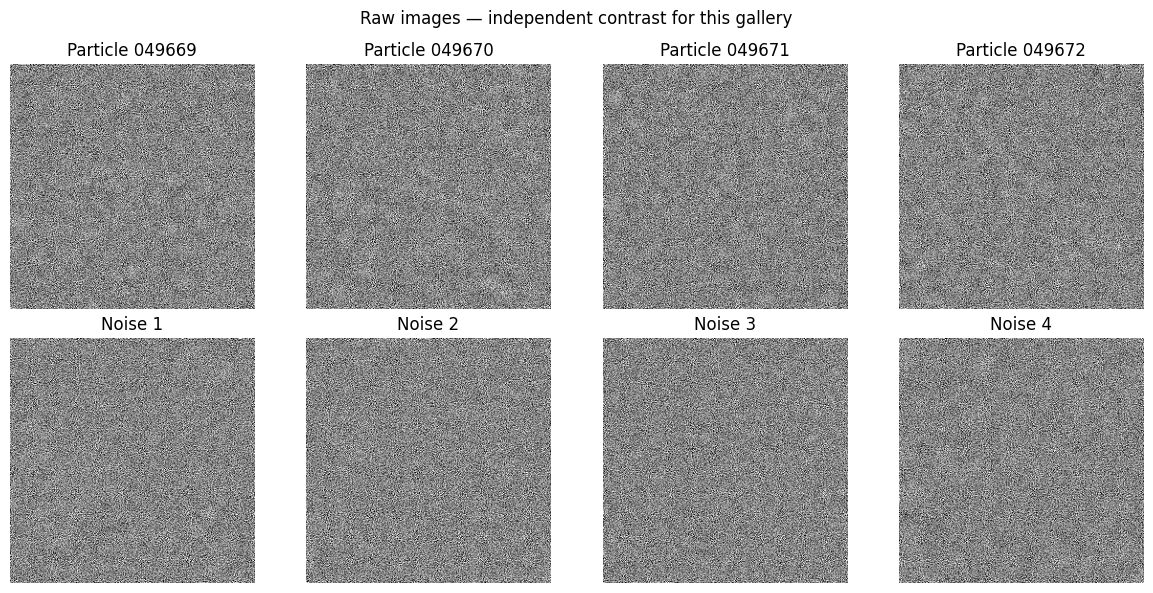

In [5]:
show_raw(particle_images, noise_images, particle_names, count=preview_count)


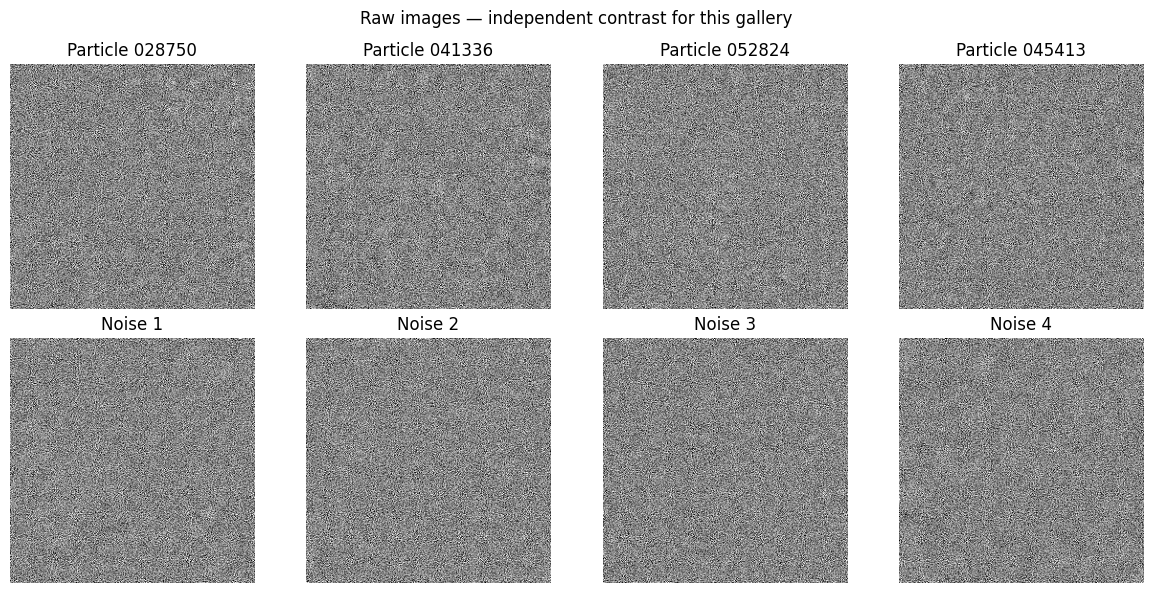

In [7]:
# ADDED: Create a reproducible random number generator.
# Using seed=42 means we get the same selection each time.
rng = np.random.default_rng(42)

# ADDED: Randomly select four particles from the 100 loaded images.
selected_indices = rng.choice(
    len(particle_images),
    size=preview_count,
    replace=False
)

# MODIFIED: Display randomly selected particles instead of the first four.
# ORIGINAL: show_raw(particle_images, noise_images, particle_names, count=preview_count)
show_raw(
    particle_images[selected_indices],
    noise_images[:preview_count],
    [particle_names[i] for i in selected_indices],
    count=preview_count
)

## 1.2. Inspect STAR metadata and recenter particles

The STAR file has 57,107 particle rows and one optics group: 256-pixel images at **1.3 Å/pixel**, 300 kV, 2.7 mm spherical aberration, and 0.1 amplitude contrast. Image names map each row to its actual stack image; row order is not stack order.

Use `rlnOriginXAngst` / `rlnOriginYAngst` to recenter observations **before low-pass filtering**. Divide by each particle's optics pixel size. Apply positive `(origin_y, origin_x)` translations in NumPy axis order, following [RELION's observation-to-reference convention](https://relion.readthedocs.io/en/latest/Reference/Conventions.html). Subpixel cubic interpolation uses reflection boundaries rather than wrapping opposite edges. These interpolated edges are not new measurements.

- `rlnAngleRot`, `rlnAngleTilt`, `rlnAnglePsi` describe 3D viewing orientation. Preserve them; a simple 2D rotation cannot align different views into one image, and recentering does not require rotating the CTF axes.
- Defocus U/V/angle, voltage, spherical aberration, and amplitude contrast remain available for CWF in section 2. Do not phase-flip here and then treat the data as uncorrected CTF observations. Phase shift and CTF B-factor are zero in this file.
- `rlnRandomSubset` records the two original half-sets and is retained. `rlnClassNumber` is 1 throughout this file; it does not label dimers versus tetramers.

Noise images have no alignment metadata. Apply particle translations cyclically as a **preprocessing control**, using the same interpolation and smoothing, so the estimated noise spectrum includes these operations. Save the assignments in `noise_transforms.csv`; these are not estimated particle positions in noise. Source MRC/STAR files are never modified.

Set `star_apply_recentering = False` only for an explicit uncentered comparison. Use the original images/metadata, not already corrected checkpoint arrays, as input. Cubic interpolation and reflection can change correlations near edges; the noise control only approximately matches those effects.


In [10]:
# ADDED: Ensure Python can find the project helper modules.
import sys
from pathlib import Path

# MODIFIED: Resolve the helper module directory relative to the project.
module_directory = str(project_root)

if module_directory not in sys.path:
    sys.path.insert(0, module_directory)

# ADDED: Check that lowpass_io.py exists.
module_path = Path(module_directory) / "lowpass_io.py"
print("File exists:", module_path.is_file())

# ORIGINAL: Import the recentering functions.
from lowpass_io import star_recentering_plan, recenter_star_images

print("lowpass_io imported successfully!")

File exists: True
lowpass_io imported successfully!


Pixel size: 1.3000 Å/pixel


,rlnVoltage,rlnImagePixelSize,rlnSphericalAberration,rlnAmplitudeContrast,rlnOpticsGroup,rlnImageSize,rlnImageDimensionality,rlnOpticsGroupName
0,300.0,1.3,2.7,0.1,3,256,2,opticsGroup3


,rlnImageName,rlnOriginXAngst,rlnOriginYAngst,rlnAngleRot,rlnAngleTilt,rlnAnglePsi,rlnDefocusU,rlnDefocusV,rlnDefocusAngle,rlnRandomSubset,rlnClassNumber
0,049669@J598/restack/batch_0_restacked.mrc,-20.544062,13.995312,163.381989,119.030304,-7.056242,17018.250000,16842.916016,-46.721073,1.0,1.0
1,049670@J598/restack/batch_0_restacked.mrc,-2.904687,-17.269688,-150.340240,129.391602,-82.390015,16970.322266,16794.988281,-46.721073,2.0,1.0
2,049671@J598/restack/batch_0_restacked.mrc,-3.115937,-12.199687,-29.071199,82.066505,-72.441399,17110.322266,16934.988281,-46.721073,1.0,1.0
3,049672@J598/restack/batch_0_restacked.mrc,10.192812,21.600311,-134.434067,132.910873,108.498589,16947.931641,16772.597656,-46.721073,1.0,1.0
4,013685@J598/restack/batch_0_restacked.mrc,12.516562,16.847187,121.144028,128.762985,98.272430,17329.041016,17214.406250,-63.691334,1.0,1.0


,applied_x_pixels,applied_y_pixels
count,100.000000,100.000000
mean,0.427203,-0.331497
std,11.173968,10.986384
min,-29.098640,-23.196873
25%,-7.881250,-7.860937
50%,-1.015625,0.528125
75%,9.628125,7.190625
max,23.115625,21.409374


Selected particles: 100; maximum shift magnitude: 29.12 pixels
Mean shift magnitude: 14.41 pixels


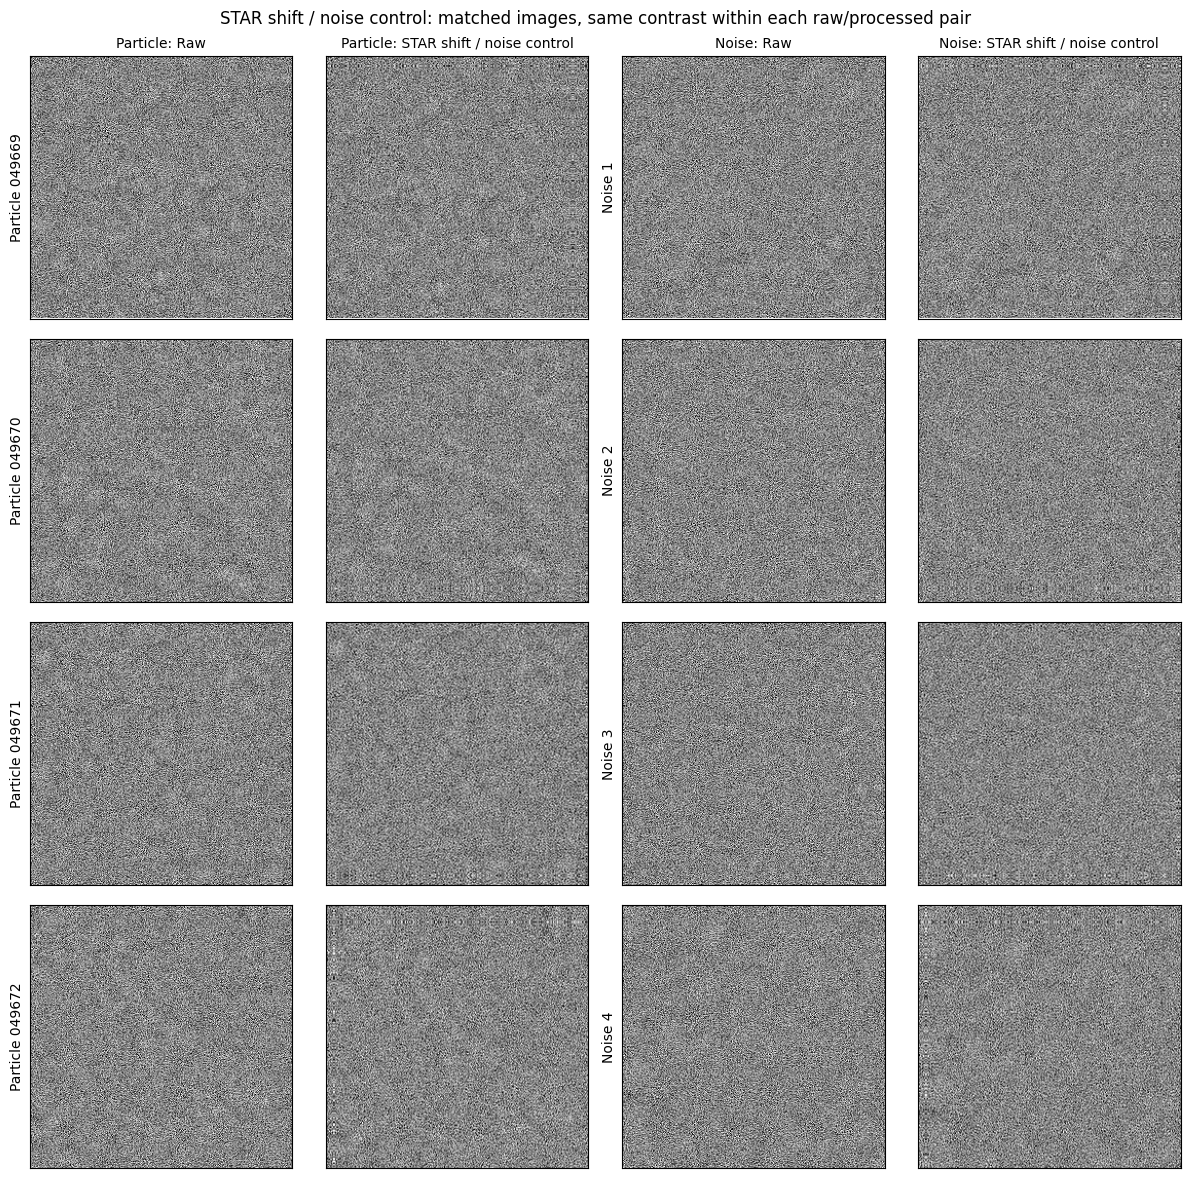

This preview shows the proposed translations. The save step applies them only if star_apply_recentering is True.


In [11]:

# ORIGINAL: Import recentering functions and MRC reader.
from lowpass_io import star_recentering_plan, recenter_star_images
import mrcfile

# ORIGINAL: Enable STAR-based recentering for the later save step.
star_apply_recentering = True

# ORIGINAL: Read MRC pixel size without loading the full image stack.
with mrcfile.mmap(str(particle_path), mode="r") as _header:
    star_pixel_size = float(_header.voxel_size.x)

# ADDED: Validate and display the pixel size.
# Reason: Incorrect pixel size would produce incorrect shifts.
if not np.isfinite(star_pixel_size) or star_pixel_size <= 0:
    raise ValueError("Invalid MRC pixel size")

print(f"Pixel size: {star_pixel_size:.4f} Å/pixel")

# ORIGINAL: Calculate recentering translations from STAR metadata.
star_shifts_xy, star_corrected_metadata = star_recentering_plan(
    particle_metadata,
    optics,
    particle_images.shape[1:],
    star_pixel_size,
)

# ORIGINAL: Display optics and particle metadata.
display(optics)

display(
    particle_metadata[
        [
            "rlnImageName",
            "rlnOriginXAngst",
            "rlnOriginYAngst",
            "rlnAngleRot",
            "rlnAngleTilt",
            "rlnAnglePsi",
            "rlnDefocusU",
            "rlnDefocusV",
            "rlnDefocusAngle",
            "rlnRandomSubset",
            "rlnClassNumber",
        ]
    ].head()
)

# ORIGINAL: Summarize calculated image shifts.
display(
    pd.DataFrame(
        star_shifts_xy,
        columns=["applied_x_pixels", "applied_y_pixels"]
    ).describe()
)

print(
    f"Selected particles: {len(particle_metadata)}; "
    f"maximum shift magnitude: "
    f"{np.linalg.norm(star_shifts_xy, axis=1).max():.2f} pixels"
)

# ADDED: Report the average shift magnitude.
# Reason: Helps us understand how much recentering is needed.
shift_magnitudes = np.linalg.norm(star_shifts_xy, axis=1)

print(
    f"Mean shift magnitude: "
    f"{shift_magnitudes.mean():.2f} pixels"
)

# ORIGINAL: Preview recentering before smoothing.
star_preview_count = min(
    preview_count,
    len(particle_images),
    len(noise_images)
)

show_pairs(
    particle_images[:star_preview_count],
    recenter_star_images(
        particle_images[:star_preview_count],
        star_shifts_xy[:star_preview_count]
    ),
    noise_images[:star_preview_count],
    recenter_star_images(
        noise_images[:star_preview_count],
        star_shifts_xy[:star_preview_count]
    ),
    particle_names[:star_preview_count],
    method="STAR shift / noise control",
    count=star_preview_count,
    input_label="Raw",
)

print(
    "This preview shows the proposed translations. "
    "The save step applies them only if "
    "star_apply_recentering is True."
)


In [13]:
# ADDED: Inspect STAR recentering shift magnitudes.
# Reason: Check whether unusually large translations occur.
# This does not modify any images.

import numpy as np

shift_magnitudes = np.linalg.norm(star_shifts_xy, axis=1)

print("Minimum shift:", round(shift_magnitudes.min(), 2), "pixels")
print("Median shift:", round(np.median(shift_magnitudes), 2), "pixels")
print("Mean shift:", round(shift_magnitudes.mean(), 2), "pixels")
print("Maximum shift:", round(shift_magnitudes.max(), 2), "pixels")

print("Particles shifted > 20 pixels:", np.sum(shift_magnitudes > 20))
print("Particles shifted > 30 pixels:", np.sum(shift_magnitudes > 30))

Minimum shift: 2.2 pixels
Median shift: 14.38 pixels
Mean shift: 14.41 pixels
Maximum shift: 29.12 pixels
Particles shifted > 20 pixels: 20
Particles shifted > 30 pixels: 0


## 1.3. Smooth low-pass filter

Apply a Gaussian low-pass filter with `lowpass_sigma_pixels = 1.0` on the original image grid. Larger sigma removes more high-frequency detail. The Gaussian response is smooth, rather than a sharp frequency cutoff. Reflection at image boundaries reduces edge discontinuities. After STAR recentering, filter each image independently and use **identical settings for particles and noise**; do not normalize individual images or resize them.

Filtering changes the signal and noise spectrum. Section 2 must use the saved filtered noise for its noise estimate. Matching this preprocessing is necessary, but it does not by itself establish the CWF model's accuracy.


In [14]:
from lowpass_io import save_lowpass_inputs, load_lowpass_inputs
import mrcfile

lowpass_sigma_pixels = 1.5  # Gaussian standard deviation in original image pixels.
lowpass_batch_size = 32


In [23]:
#1.3b
# ADDED: Prepare the complete particle dataset using memory mapping.

import numpy as np
import mrcfile
from pathlib import Path

# ORIGINAL: Use the existing project and particle paths.
output_root = project_root / "outputs"
output_root.mkdir(parents=True, exist_ok=True)

# ADDED: Store the new array on disk, not in RAM.
full_stack_path = output_root / "raw_particles_star_order.npy"

# ADDED: Prevent accidental overwriting of an existing file.
if full_stack_path.exists():
    raise FileExistsError(
        f"Output already exists: {full_stack_path}"
    )

# ORIGINAL LOGIC: Preserve STAR particle ordering.
# The STAR rows do not follow the original MRC stack order.
full_particle_metadata = particles.loc[
    refs[1] == stack_reference
].copy().reset_index(drop=True)

full_indices = (
    full_particle_metadata["rlnImageName"]
    .str.split("@", n=1)
    .str[0]
    .astype(np.int64)
    .to_numpy() - 1
)

# ADDED: Check all references before copying images.
assert len(full_indices) == 57107
assert len(np.unique(full_indices)) == len(full_indices)

# ADDED: Read the original MRC file using memory mapping.
with mrcfile.mmap(str(particle_path), mode="r") as mrc:

    if np.any(full_indices < 0) or np.any(full_indices >= len(mrc.data)):
        raise IndexError("STAR references outside MRC stack")

    # ADDED: Create an output array stored on disk.
    full_particle_images = np.lib.format.open_memmap(
        full_stack_path,
        mode="w+",
        dtype=np.float32,
        shape=(len(full_indices), 256, 256)
    )

    # ADDED: Process only 32 images at a time.
    batch_size = 32

    for start in range(0, len(full_indices), batch_size):

        stop = min(start + batch_size, len(full_indices))

        # MODIFIED: Load only the current batch.
        # Original load_raw_dataset assembled the entire
        # selected dataset into an in-memory float32 array.
        full_particle_images[start:stop] = np.asarray(
            mrc.data[full_indices[start:stop]],
            dtype=np.float32
        )

        if start % 5000 < batch_size:
            print(f"Prepared {stop:,} / {len(full_indices):,} particles")

    # ADDED: Ensure data is written to disk.
    full_particle_images.flush()

print("Full dataset prepared.")
print("Shape:", full_particle_images.shape)
print("Data type:", full_particle_images.dtype)
print("Saved to:", full_stack_path)


Prepared 32 / 57,107 particles
Prepared 5,056 / 57,107 particles
Prepared 10,048 / 57,107 particles
Prepared 15,040 / 57,107 particles
Prepared 20,032 / 57,107 particles
Prepared 25,056 / 57,107 particles
Prepared 30,048 / 57,107 particles
Prepared 35,040 / 57,107 particles
Prepared 40,032 / 57,107 particles
Prepared 45,056 / 57,107 particles
Prepared 50,048 / 57,107 particles
Prepared 55,040 / 57,107 particles
Full dataset prepared.
Shape: (57107, 256, 256)
Data type: float32
Saved to: /Users/kr/ml4ls/outputs/raw_particles_star_order.npy


In [4]:
#### 1.3c — Create three-fold CV and held-out unknown test set.

# MODIFIED: Create 3 CV folds plus a separate held-out test group.
# Original plan: All particles divided into 3 folds.
# New plan: 10% unknown/test, 90% divided into 3 CV folds.
#
# IMPORTANT: This is particle-level splitting because
# micrograph identifiers are unavailable.

import numpy as np
import pandas as pd
from pathlib import Path

# ORIGINAL: Keep STAR particle ordering and stable IDs.
particle_ids = full_particle_metadata["rlnImageName"].astype(str)

if not particle_ids.is_unique:
    raise ValueError("Duplicate particle IDs found.")

n_particles = len(particle_ids)

# ADDED: Reproducible random selection.
rng = np.random.default_rng(42)
shuffled = rng.permutation(n_particles)

# ADDED: Reserve 10% for the untouched test group.
n_test = int(np.ceil(n_particles * 0.10))

test_indices = shuffled[:n_test]
development_indices = shuffled[n_test:]

# MODIFIED: Create three folds using development particles only.
folds = np.zeros(n_particles, dtype=np.int8)

for fold_number, indices in enumerate(
    np.array_split(development_indices, 3),
    start=1
):
    folds[indices] = fold_number

# ADDED: Fold 0 indicates held-out test particles.
folds[test_indices] = 0

# ADDED: Explicit split names for clarity.
split_labels = np.where(
    folds == 0,
    "unknown_test",
    "cross_validation"
)

# MODIFIED: Save the four-group manifest.
cv_manifest = pd.DataFrame({
    "particle_id": particle_ids.to_numpy(),
    "star_row": np.arange(n_particles),
    "stack_index_1based": full_indices + 1,
    "split": split_labels,
    "cv_fold": folds
})

split_dir = project_root / "outputs" / "validation"
split_dir.mkdir(parents=True, exist_ok=True)

# ADDED: Use a new filename to distinguish this protocol.
split_path = split_dir / "cv_3fold_with_unknown_test.csv"

if split_path.exists():
    raise FileExistsError(
        f"Existing split found: {split_path}. "
        "Do not overwrite a previously used evaluation split."
    )

cv_manifest.to_csv(split_path, index=False)

print("Saved:", split_path)

print("\nParticle counts:")
print(
    cv_manifest["cv_fold"]
    .value_counts()
    .sort_index()
)

print("\nTotal:", len(cv_manifest))


NameError: name 'full_particle_metadata' is not defined

## 1.4. Apply and save

Filter in batches directly to disk, keeping original pixel size and row order. Each run creates `outputs/lowpass_*` with `particles.npy`, `noise.mrc`, particle metadata, optics, and filter settings. The latest completed folder is selected by section 2 by default. Existing runs are not overwritten; no CWF calculation is needed here.

With STAR recentering enabled, save original metadata separately and zero the applied origins in `particles.csv` to prevent applying them again. Original origins, applied pixel shifts, and the explicit noise-control translation assignments are saved. Rotations and CTF parameters are preserved.


In [26]:
# ADDED: Verify the full particle dataset and CV manifest.
# Reason: Ensure image rows match STAR metadata and CV assignments.
# This is memory-safe for your Mac M3 with 8 GB RAM.

import numpy as np
import pandas as pd

full_particle_images = np.load(
    project_root / "outputs" / "raw_particles_star_order.npy",
    mmap_mode="r"
)

cv_manifest = pd.read_csv(
    project_root / "outputs" / "validation"
    / "cv_3fold_with_unknown_test.csv"
)

# ADDED: Check consistency.
assert full_particle_images.shape == (57107, 256, 256)
assert len(cv_manifest) == len(full_particle_images)
assert cv_manifest["particle_id"].is_unique
assert np.array_equal(
    cv_manifest["star_row"].to_numpy(),
    np.arange(len(full_particle_images))
)
assert np.array_equal(
    cv_manifest["particle_id"].astype(str).to_numpy(),
    full_particle_metadata["rlnImageName"].astype(str).to_numpy()
)

print("Full dataset verification: PASSED")
print("Images:", full_particle_images.shape)
print("CV groups:", cv_manifest["cv_fold"].value_counts().sort_index().to_dict())

Full dataset verification: PASSED
Images: (57107, 256, 256)
CV groups: {0: 5711, 1: 17132, 2: 17132, 3: 17132}


In [16]:
### 1.4a
# ORIGINAL: Read pixel size from the input MRC file.
with mrcfile.mmap(str(particle_path), mode="r") as _particle_header:
    lowpass_pixel_size = float(_particle_header.voxel_size.x)


# ADDED: Confirm that we are still processing only 100 particles.
# Reason: Avoid accidentally processing a much larger dataset
# on your Mac M3 with 8 GB RAM.
assert len(particle_images) == 100, (
    "Expected 100 test particles. "
    "Check particle_count before continuing."
)


# ADDED: Display the settings before saving.
print("Particles to process:", len(particle_images))
print("Noise images to process:", len(noise_images))
print("Gaussian sigma:", lowpass_sigma_pixels)
print("Batch size:", lowpass_batch_size)
print("STAR recentering enabled:", star_apply_recentering)


# ORIGINAL: Apply STAR recentering and Gaussian low-pass filtering.
# The helper function creates a new output directory.
lowpass_directory = save_lowpass_inputs(
    particle_images,
    noise_images,
    particle_metadata,
    optics,
    project_root / "outputs",
    pixel_size=lowpass_pixel_size,
    sigma_pixels=lowpass_sigma_pixels,
    batch_size=lowpass_batch_size,
    recenter_from_star=star_apply_recentering,
    source_paths={
        "particles": str(particle_path),
        "noise": str(noise_path),
        "star": str(star_path)
    },
)


# ORIGINAL: Reload the saved checkpoint.
# Particle images use memory mapping; noise images are copied into RAM.
lowpass_result = load_lowpass_inputs(
    project_root / "outputs",
    directory=lowpass_directory
)


# ORIGINAL: Display the saved result information.
print(f"Saved low-pass inputs: {lowpass_directory}")

print(
    f"Particles: {lowpass_result['particles'].shape}; "
    f"noise: {lowpass_result['noise'].shape}"
)

print(
    f"Sigma: {lowpass_sigma_pixels} pixels = "
    f"{lowpass_sigma_pixels * lowpass_pixel_size:.2f} Å"
)



Particles to process: 100
Noise images to process: 1314
Gaussian sigma: 1.5
Batch size: 32
STAR recentering enabled: True
Saved low-pass inputs: /Users/kr/ml4ls/outputs/lowpass_al6tk73y
Particles: (100, 256, 256); noise: (1314, 256, 256)
Sigma: 1.5 pixels = 1.95 Å


In [27]:
### 1.4b — Full-dataset low-pass preprocessing (memory-efficient)

# ADDED: Full-dataset preprocessing for Apple M3 / 8 GB RAM.
# Reason: Process all 57,107 particles using disk-backed
# arrays instead of loading the entire dataset into RAM.

from pathlib import Path
import numpy as np
import json

# ADDED: Open the full particle dataset using memory mapping.
# This does NOT load all particles into RAM.
full_particle_images = np.load(
    project_root / "outputs" / "raw_particles_star_order.npy",
    mmap_mode="r"
)

# ADDED: Verify full-dataset inputs.
assert full_particle_images.shape == (57107, 256, 256)
assert len(full_particle_metadata) == 57107
assert len(noise_images) == 1314

# ORIGINAL: Keep preprocessing settings unchanged.
# These were successfully tested with 100 particles.
lowpass_sigma_pixels = 1.5
lowpass_batch_size = 32
star_apply_recentering = True

# ADDED: Protect against accidentally repeating this job.
# The original save function creates a new output directory
# every time it is called.
completion_file = (
    project_root / "outputs" / "full_lowpass_checkpoint.txt"
)

if completion_file.exists():
    raise FileExistsError(
        "A completed full-dataset checkpoint is already recorded: "
        f"{completion_file}"
    )

print("Processing particles:", len(full_particle_images))
print("Processing noise:", len(noise_images))
print("Batch size:", lowpass_batch_size)
print("Gaussian sigma:", lowpass_sigma_pixels)
print("STAR recentering:", star_apply_recentering)

# MODIFIED: Use full_particle_images rather than particle_images.
# MODIFIED: Use full_particle_metadata rather than particle_metadata.
# ORIGINAL: Keep the same save_lowpass_inputs algorithm.
full_lowpass_directory = save_lowpass_inputs(
    full_particle_images,
    noise_images,
    full_particle_metadata,
    optics,
    project_root / "outputs",
    pixel_size=lowpass_pixel_size,
    sigma_pixels=lowpass_sigma_pixels,
    batch_size=lowpass_batch_size,
    recenter_from_star=star_apply_recentering,
    source_paths={
        "particles": str(particle_path),
        "noise": str(noise_path),
        "star": str(star_path)
    },
)

# ADDED: Verify saved particle array without loading it fully.
processed = np.load(
    full_lowpass_directory / "particles.npy",
    mmap_mode="r"
)

assert processed.shape == (57107, 256, 256)

# ADDED: Record the successful output path.
# Reason: Avoid accidental duplicate preprocessing runs.
completion_file.write_text(str(full_lowpass_directory) + "\n")

print("\nFull preprocessing completed successfully!")
print("Processed shape:", processed.shape)
print("Saved to:", full_lowpass_directory)
print("Checkpoint recorded:", completion_file)


Processing particles: 57107
Processing noise: 1314
Batch size: 32
Gaussian sigma: 1.5
STAR recentering: True

Full preprocessing completed successfully!
Processed shape: (57107, 256, 256)
Saved to: /Users/kr/ml4ls/outputs/lowpass_4wpik5am
Checkpoint recorded: /Users/kr/ml4ls/outputs/full_lowpass_checkpoint.txt


In [28]:
# ADDED: Validate the complete low-pass checkpoint.
# Reason: Check the saved images and particle IDs before
# continuing to the next notebook.
# Memory-safe: samples image data instead of loading all images.

from pathlib import Path
import numpy as np
import pandas as pd

# MODIFIED: Same checkpoint, located relative to the project root.
checkpoint = project_root / "outputs" / "lowpass_4wpik5am"

# ADDED: Open processed images using memory mapping.
processed = np.load(
    checkpoint / "particles.npy",
    mmap_mode="r"
)

# ADDED: Load saved metadata and fold assignments.
processed_metadata = pd.read_csv(
    checkpoint / "particles.csv"
)

cv_manifest = pd.read_csv(
    project_root / "outputs" / "validation"
    / "cv_3fold_with_unknown_test.csv"
)

# ADDED: Verify dimensions and particle ordering.
assert processed.shape == (57107, 256, 256)
assert len(processed_metadata) == len(processed)
assert len(cv_manifest) == len(processed)

assert np.array_equal(
    processed_metadata["rlnImageName"].astype(str).to_numpy(),
    cv_manifest["particle_id"].astype(str).to_numpy()
), "Particle IDs do not match!"

# ADDED: Check a small, reproducible sample for invalid values.
rng = np.random.default_rng(42)
sample_indices = rng.choice(len(processed), size=100, replace=False)

for idx in sample_indices:
    if not np.isfinite(processed[idx]).all():
        raise ValueError(f"Invalid pixel values in particle {idx}")

print("Full checkpoint verification: PASSED")
print("Processed images:", processed.shape)
print("Data type:", processed.dtype)
print("Particle IDs aligned:", True)
print("Sampled image quality check:", "PASSED")
print("CV folds:", cv_manifest["cv_fold"].value_counts().sort_index().to_dict())

Full checkpoint verification: PASSED
Processed images: (57107, 256, 256)
Data type: float32
Particle IDs aligned: True
Sampled image quality check: PASSED
CV folds: {0: 5711, 1: 17132, 2: 17132, 3: 17132}


## 1.5. Display raw and corrected/filtered images

Each pair uses the same image and contrast limits. Section 1's original raw arrays remain unchanged. Smoothing alone does not prove recovery of particle detail.


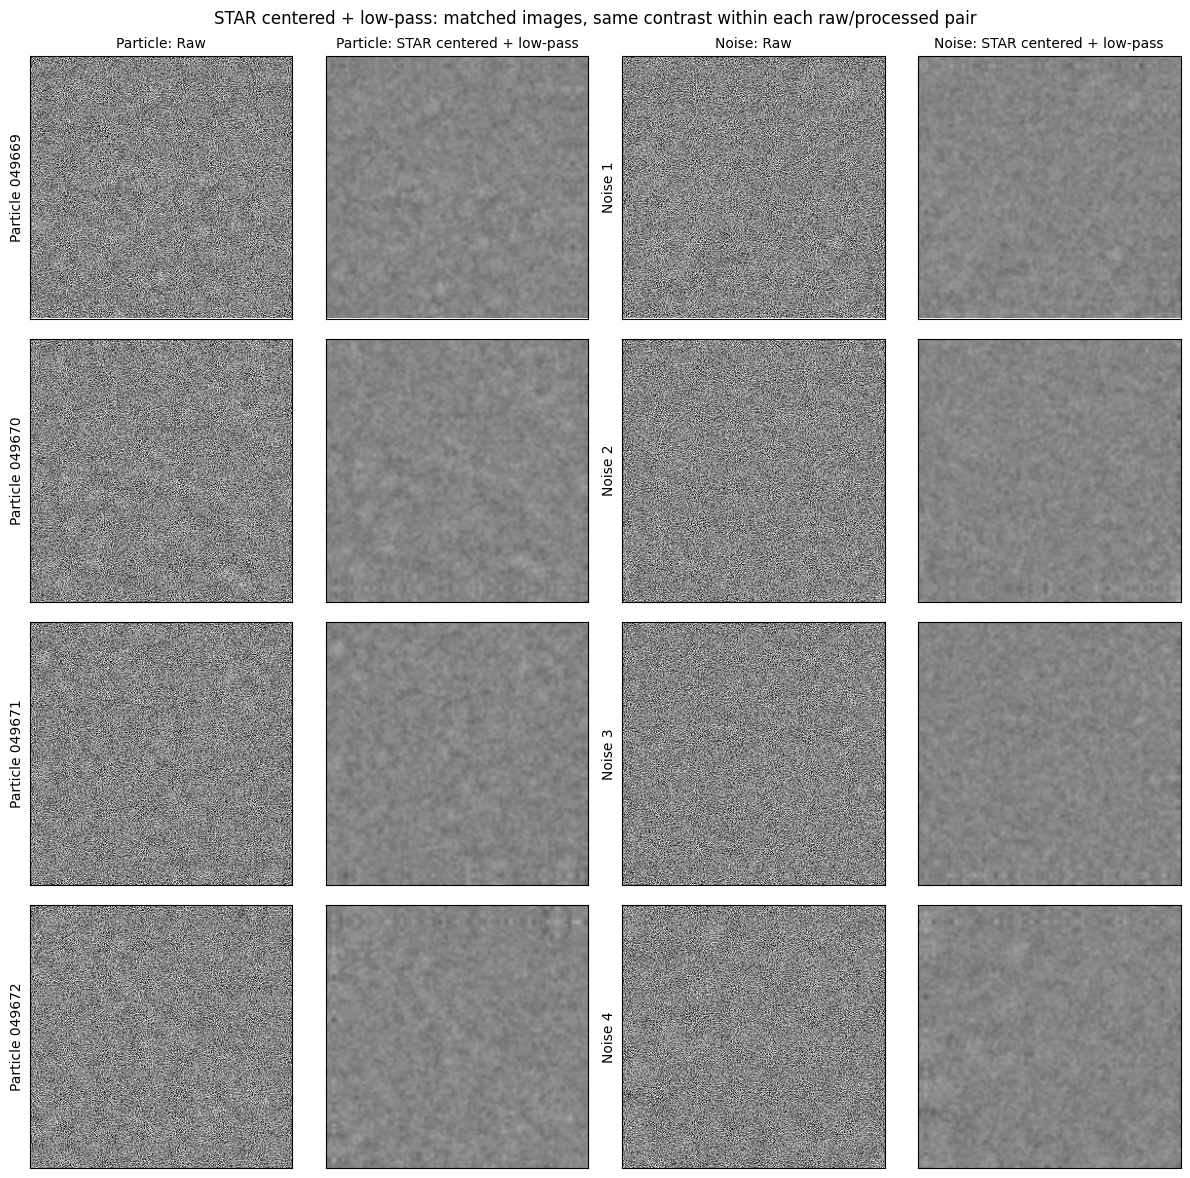

In [17]:
show_pairs(
    particle_images[:preview_count], lowpass_result["particles"][:preview_count],
    noise_images[:preview_count], lowpass_result["noise"][:preview_count],
    particle_names[:preview_count], method="STAR centered + low-pass" if star_apply_recentering else "Gaussian low-pass", count=preview_count,
    input_label="Raw",
)


In [18]:
# ADDED: Verify the saved output checkpoint.
# Reason: Confirm that Section 1.4 saved the expected
# images and metadata before proceeding to Notebook 02.

from pathlib import Path

output_dir = Path(lowpass_directory)

print("Output directory:", output_dir)

for filename in [
    "particles.npy",
    "noise.mrc",
    "particles.csv",
    "optics.csv",
    "settings.json",
]:
    path = output_dir / filename
    print(f"{filename}: {'OK' if path.is_file() else 'MISSING'}")

Output directory: /Users/kr/ml4ls/outputs/lowpass_al6tk73y
particles.npy: OK
noise.mrc: OK
particles.csv: OK
optics.csv: OK
settings.json: OK


In [19]:
# ADDED: Check available disk space.
# Reason: Full-dataset preprocessing will create
# large output files on your Mac.

import shutil

total, used, free = shutil.disk_usage(project_root)  # MODIFIED: Portable project path

print(f"Total disk: {total / 1024**3:.1f} GiB")
print(f"Used disk:  {used / 1024**3:.1f} GiB")
print(f"Free disk:  {free / 1024**3:.1f} GiB")

Total disk: 460.4 GiB
Used disk:  365.7 GiB
Free disk:  94.7 GiB


In [20]:
# ADDED: Check the memory-mapping support available.
# Reason: Prepare for processing 57,107 images
# without loading the entire stack into RAM.

import numpy as np
import mrcfile

print("NumPy version:", np.__version__)

with mrcfile.mmap(str(particle_path), mode="r") as mrc:
    print("Input image shape:", mrc.data.shape)
    print("Input data type:", mrc.data.dtype)
    print("Memory mapped:", isinstance(mrc.data, np.memmap))

NumPy version: 1.26.4
Input image shape: (57107, 256, 256)
Input data type: float16
Memory mapped: True


In [21]:
# ADDED: Check STAR particle references before full processing.
# Reason: Verify that the full dataset can be matched to the MRC stack.
# This only reads metadata, not particle image data.

import starfile
import pandas as pd

tables = starfile.read(star_path, always_dict=True)
particles = tables["particles"]

# ORIGINAL LOGIC: Separate image index from stack reference.
refs = particles["rlnImageName"].astype(str).str.split(
    "@", n=1, expand=True
)

# ADDED: Count references matching the existing stack_reference.
matches = refs[1] == stack_reference

print("Total STAR particle rows:", len(particles))
print("Matching stack references:", matches.sum())
print("Unique matching image indices:", refs.loc[matches, 0].nunique())

print("\nExample STAR references:")
print(particles["rlnImageName"].head())

Total STAR particle rows: 57107
Matching stack references: 57107
Unique matching image indices: 57107

Example STAR references:
0    049669@J598/restack/batch_0_restacked.mrc
1    049670@J598/restack/batch_0_restacked.mrc
2    049671@J598/restack/batch_0_restacked.mrc
3    049672@J598/restack/batch_0_restacked.mrc
4    013685@J598/restack/batch_0_restacked.mrc
Name: rlnImageName, dtype: str


In [22]:
# ADDED: Estimate memory and disk requirements.
# Reason: Plan full-dataset processing safely on an 8 GB Mac.

import numpy as np
import shutil

n_particles = 57107
n_noise = 1314
height = 256
width = 256

n_images = n_particles + n_noise

float32_bytes = (
    n_images * height * width *
    np.dtype(np.float32).itemsize
)

free_bytes = shutil.disk_usage(project_root).free

print(f"Total images: {n_images:,}")
print(f"Float32 dataset size: {float32_bytes / 1024**3:.2f} GiB")
print(f"Available disk: {free_bytes / 1024**3:.2f} GiB")

Total images: 58,421
Float32 dataset size: 14.26 GiB
Available disk: 94.70 GiB


In [24]:
# ADDED: Inspect STAR metadata for three-fold cross-validation.
# Reason: Determine whether particles can be grouped by micrograph.
# No image data will be loaded.

print("Available STAR columns:")
print(particles.columns.tolist())

if "rlnMicrographName" in particles.columns:
    print(
        "\nNumber of unique micrographs:",
        particles["rlnMicrographName"].nunique()
    )
else:
    print("\nMicrograph information is unavailable.")

Available STAR columns:
['rlnImageName', 'rlnAngleRot', 'rlnAngleTilt', 'rlnAnglePsi', 'rlnOriginXAngst', 'rlnOriginYAngst', 'rlnDefocusU', 'rlnDefocusV', 'rlnDefocusAngle', 'rlnPhaseShift', 'rlnCtfBfactor', 'rlnOpticsGroup', 'rlnRandomSubset', 'rlnClassNumber']

Micrograph information is unavailable.
